<a href="https://colab.research.google.com/github/Ahmettufan3310/74-musteri-segmentasyonu-rfm/blob/main/notebooks/01_veri_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
!pip install ucimlrepo -q

In [14]:
from ucimlrepo import fetch_ucirepo
df = fetch_ucirepo(id=352).data.original
print(df.shape)
print(df.columns.tolist())

(541909, 8)
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [15]:
toplam = len(df)
bos_musteri = df['CustomerID'].isna().sum()
iptal = df['InvoiceNo'].astype(str).str.startswith('C').sum()
adet_kotu = (df['Quantity'] <= 0).sum()
fiyat_kotu = (df['UnitPrice'] <= 0).sum()

temiz = df.dropna(subset=['CustomerID'])
temiz = temiz[~temiz['InvoiceNo'].astype(str).str.startswith('C')]
temiz = temiz[(temiz['Quantity'] > 0) & (temiz['UnitPrice'] > 0)]

print("Toplam satır:", toplam)
print("Müşteri numarası boş:", bos_musteri, f"(%{bos_musteri/toplam*100:.1f})")
print("İptal/iade faturası (C ile başlayan):", iptal)
print("Adedi sıfır veya negatif:", adet_kotu)
print("Fiyatı sıfır veya negatif:", fiyat_kotu)
print("Temizlik sonrası kalan satır:", len(temiz))
print("Temizlik sonrası müşteri sayısı:", temiz['CustomerID'].nunique())

Toplam satır: 541909
Müşteri numarası boş: 135080 (%24.9)
İptal/iade faturası (C ile başlayan): 9288
Adedi sıfır veya negatif: 10624
Fiyatı sıfır veya negatif: 2517
Temizlik sonrası kalan satır: 397884
Temizlik sonrası müşteri sayısı: 4338


In [16]:
ilginc = temiz[~temiz['StockCode'].astype(str).str.match(r'^\d{5}')]
print(ilginc['StockCode'].value_counts())

StockCode
POST            1099
M                284
C2               133
DOT               16
BANK CHARGES      12
PADS               3
Name: count, dtype: int64


In [17]:
cikar = ['POST', 'M', 'C2', 'DOT', 'BANK CHARGES', 'PADS']
once = len(temiz)
temiz = temiz[~temiz['StockCode'].astype(str).isin(cikar)]
print("Çıkarılan satır:", once - len(temiz))
print("Kalan satır:", len(temiz))
print("Kalan müşteri:", temiz['CustomerID'].nunique())

Çıkarılan satır: 1547
Kalan satır: 396337
Kalan müşteri: 4334


In [18]:
print(temiz[['Quantity', 'UnitPrice']].describe(percentiles=[0.5, 0.99, 0.999]))

            Quantity      UnitPrice
count  396337.000000  396337.000000
mean       13.012547       2.868222
std       179.641245       4.264663
min         1.000000       0.040000
50%         6.000000       1.950000
99%       120.000000      12.750000
99.9%     504.000000      33.175760
max     80995.000000     649.500000


In [19]:
sutunlar = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'CustomerID']
print("--- En yüksek adetli 10 satır ---")
print(temiz.nlargest(10, 'Quantity')[sutunlar])
print("--- En yüksek fiyatlı 10 satır ---")
print(temiz.nlargest(10, 'UnitPrice')[sutunlar])

--- En yüksek adetli 10 satır ---
       InvoiceNo StockCode                          Description  Quantity  \
540421    581483     23843          PAPER CRAFT , LITTLE BIRDIE     80995   
61619     541431     23166       MEDIUM CERAMIC TOP STORAGE JAR     74215   
421632    573008     84077    WORLD WAR 2 GLIDERS ASSTD DESIGNS      4800   
206121    554868     22197                 SMALL POPCORN HOLDER      4300   
97432     544612     22053                EMPIRE DESIGN ROSETTE      3906   
270885    560599     18007  ESSENTIAL BALM 3.5g TIN IN ENVELOPE      3186   
52711     540815     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114   
160546    550461     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114   
433788    573995     16014          SMALL CHINESE STYLE SCISSOR      3000   
4945      536830     84077    WORLD WAR 2 GLIDERS ASSTD DESIGNS      2880   

        UnitPrice  CustomerID  
540421       2.08     16446.0  
61619        1.04     12346.0  
421632       0.21     

In [20]:
kontrol = [(16446, '23843'), (12346, '23166'), (15098, '22502'), (15749, '21108')]
for musteri, urun in kontrol:
    print(f"--- Müşteri {int(musteri)}, ürün {urun} ---")
    satirlar = df[(df['CustomerID'] == musteri) & (df['StockCode'].astype(str) == urun)]
    print(satirlar[['InvoiceNo', 'InvoiceDate', 'Quantity', 'UnitPrice']])

--- Müşteri 16446, ürün 23843 ---
       InvoiceNo     InvoiceDate  Quantity  UnitPrice
540421    581483  12/9/2011 9:15     80995       2.08
540422   C581484  12/9/2011 9:27    -80995       2.08
--- Müşteri 12346, ürün 23166 ---
      InvoiceNo      InvoiceDate  Quantity  UnitPrice
61619    541431  1/18/2011 10:01     74215       1.04
61624   C541433  1/18/2011 10:17    -74215       1.04
--- Müşteri 15098, ürün 22502 ---
       InvoiceNo      InvoiceDate  Quantity  UnitPrice
222670    556442  6/10/2011 15:22        60       4.95
222680    556444  6/10/2011 15:28        60     649.50
222682    556446  6/10/2011 15:33         1     649.50
222692   C556448  6/10/2011 15:39       -60       4.95
--- Müşteri 15749, ürün 21108 ---
       InvoiceNo      InvoiceDate  Quantity  UnitPrice
52711     540815  1/11/2011 12:55      3114        2.1
160145   C550456  4/18/2011 13:08     -3114        2.1
160546    550461  4/18/2011 13:20      3114        2.1


In [21]:
hatali = [('581483', '23843'), ('541431', '23166'), ('540815', '21108'), ('556444', '22502')]
once = len(temiz)
for fatura, urun in hatali:
    temiz = temiz[~((temiz['InvoiceNo'].astype(str) == fatura) & (temiz['StockCode'].astype(str) == urun))]
print("Çıkarılan satır:", once - len(temiz))
print("Kalan satır:", len(temiz))
print("Kalan müşteri:", temiz['CustomerID'].nunique())

Çıkarılan satır: 4
Kalan satır: 396333
Kalan müşteri: 4333


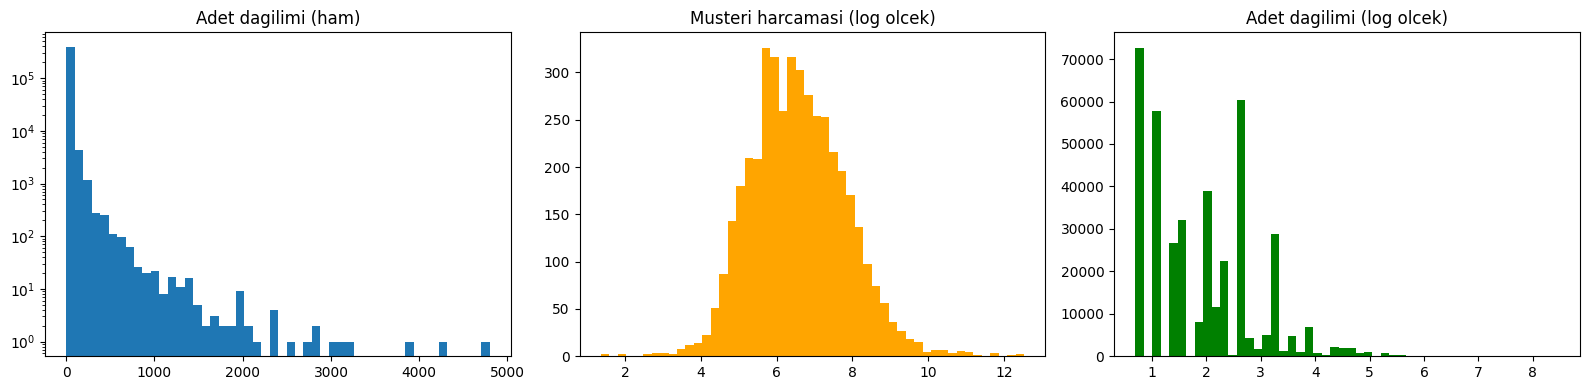

In [22]:
import matplotlib.pyplot as plt
import numpy as np

temiz['Tutar'] = temiz['Quantity'] * temiz['UnitPrice']
musteri_harcama = temiz.groupby('CustomerID')['Tutar'].sum()

fig, eksen = plt.subplots(1, 3, figsize=(16, 4))

eksen[0].hist(temiz['Quantity'], bins=50)
eksen[0].set_title('Adet dagilimi (ham)')
eksen[0].set_yscale('log')

eksen[1].hist(np.log1p(musteri_harcama), bins=50, color='orange')
eksen[1].set_title('Musteri harcamasi (log olcek)')

eksen[2].hist(np.log1p(temiz['Quantity']), bins=50, color='green')
eksen[2].set_title('Adet dagilimi (log olcek)')

plt.tight_layout()
plt.show()

In [23]:
# iptaller (C ile başlayanlar)
iptaller = df[df['InvoiceNo'].astype(str).str.startswith('C')].copy()
iptaller['Quantity'] = iptaller['Quantity'].abs()

# aynı müşteri + ürün + adet ile iptali olanlar
anahtar_temiz = temiz['CustomerID'].astype(str) + '_' + temiz['StockCode'].astype(str) + '_' + temiz['Quantity'].astype(str)
anahtar_iptal = iptaller['CustomerID'].astype(str) + '_' + iptaller['StockCode'].astype(str) + '_' + iptaller['Quantity'].astype(str)

eslesmis = anahtar_temiz.isin(set(anahtar_iptal))
print("İptali olan ama hâlâ duran satır:", eslesmis.sum())
print(temiz[eslesmis]['Quantity'].describe())

İptali olan ama hâlâ duran satır: 5303
count    5303.000000
mean       22.962474
std        96.902279
min         1.000000
25%         1.000000
50%         4.000000
75%        12.000000
max      3114.000000
Name: Quantity, dtype: float64


In [24]:
kopya_sayisi = temiz.duplicated().sum()
print("Tam kopya (birebir aynı) satır sayısı:", kopya_sayisi)

once = len(temiz)
temiz = temiz.drop_duplicates()
print("Çıkarılan kopya:", once - len(temiz))
print("Son kalan satır:", len(temiz))
print("Son müşteri sayısı:", temiz['CustomerID'].nunique())

Tam kopya (birebir aynı) satır sayısı: 5187
Çıkarılan kopya: 5187
Son kalan satır: 391146
Son müşteri sayısı: 4333
